# Twitter Sentiment Analysis
Sentiment analysis means finding out if a piece of text is positive, negative or neutral. This project uses five models for this task on tweets: four Machine Learning models (Naive Bayes, Random Forest, Decision Tree, KNN) trained on TF-IDF features, and one Deep Learning model (CNN) trained on tokenized sequences. All five are tested on the same test set for fair comparison.


## 1. Libraries
This cell imports all the libraries needed for the project. NLTK is used for text preprocessing, scikit-learn for the ML models and evaluation, and TensorFlow/Keras for the CNN. A few NLTK resource packages also need to be downloaded before they can be used.


In [36]:
!pip install -q nltk scikit-learn tensorflow matplotlib seaborn kaggle

import nltk
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')

import re
import string
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Dense, Dropout, Embedding, Conv1D,
                                      GlobalMaxPooling1D, BatchNormalization,
                                      SpatialDropout1D, Concatenate)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

SEED = 42
np.random.seed(SEED)

print('Libraries loaded.')

Libraries loaded.


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## 2. Loading the Dataset
The dataset used is the Tweet Sentiment Extraction dataset from Kaggle, with tweets labeled as negative, neutral or positive. The train and test files are combined into one dataframe so the data can be split again later. The sentiment labels are also mapped to numbers (0 = negative, 1 = neutral, 2 = positive) since models need numeric labels.


In [37]:
os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

!kaggle competitions download -c tweet-sentiment-extraction
!unzip -oq tweet-sentiment-extraction.zip -d tweet_data

train_df = pd.read_csv('tweet_data/train.csv')[['text', 'sentiment']]
test_df = pd.read_csv('tweet_data/test.csv')[['text', 'sentiment']]

df = pd.concat([train_df, test_df], ignore_index=True)
df = df.rename(columns={'text': 'tweet'})
df = df.dropna(subset=['tweet', 'sentiment']).reset_index(drop=True)

label_map = {'negative': 0, 'neutral': 1, 'positive': 2}
df['label'] = df['sentiment'].map(label_map)
df = df.dropna(subset=['label']).reset_index(drop=True)
df['label'] = df['label'].astype(int)

print('Total tweets:', len(df))
print(df['sentiment'].value_counts())
df.head()

tweet-sentiment-extraction.zip: Skipping, found more recently modified local copy (use --force to force download)
Total tweets: 31014
sentiment
neutral     12547
positive     9685
negative     8782
Name: count, dtype: int64


,tweet,sentiment,label
0,"I`d have responded, if I were going",neutral,1
1,Sooo SAD I will miss you here in San Diego!!!,negative,0
2,my boss is bullying me...,negative,0
3,what interview! leave me alone,negative,0
4,"Sons of ****, why couldn`t they put them on t...",negative,0


This plot shows how many tweets belong to each sentiment class, which gives an idea of the class balance in the dataset.


/tmp/ipykernel_2849/3089394314.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='sentiment', data=df, order=['negative','neutral','positive'],


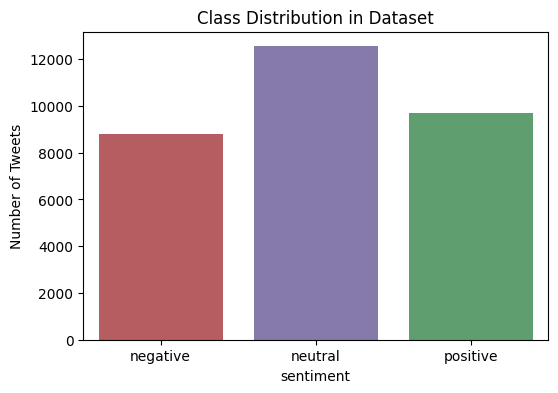

In [38]:
plt.figure(figsize=(6,4))
sns.countplot(x='sentiment', data=df, order=['negative','neutral','positive'],
              palette=['#C44E52','#8172B2','#55A868'])
plt.title('Class Distribution in Dataset')
plt.ylabel('Number of Tweets')
plt.show()

## 3. Text Preprocessing
Raw tweets contain links, mentions, hashtags, punctuation and numbers, none of which carry sentiment. This cell cleans the text by lowercasing it, removing these unwanted parts, and then tokenizing and lemmatizing the remaining words while removing stopwords.


In [39]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_tweet(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\d+', '', text)
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words and len(w) > 1]
    return ' '.join(tokens)

df['clean_tweet'] = df['tweet'].apply(clean_tweet)
df = df[df['clean_tweet'].str.strip() != ''].reset_index(drop=True)

df[['tweet', 'clean_tweet', 'sentiment']].head(10)

,tweet,clean_tweet,sentiment
0,"I`d have responded, if I were going",id responded going,neutral
1,Sooo SAD I will miss you here in San Diego!!!,sooo sad miss san diego,negative
2,my boss is bullying me...,bos bullying,negative
3,what interview! leave me alone,interview leave alone,negative
4,"Sons of ****, why couldn`t they put them on t...",son couldnt put release already bought,negative
5,http://www.dothebouncy.com/smf - some shameles...,shameless plugging best ranger forum earth,neutral
6,2am feedings for the baby are fun when he is a...,feeding baby fun smile coo,positive
7,Soooo high,soooo high,neutral
8,Journey!? Wow... u just became cooler. hehe....,journey wow became cooler hehe possible,positive
9,"as much as i love to be hopeful, i reckon the...",much love hopeful reckon chance minimal im nev...,neutral


## 4. Train / Test Split
The cleaned tweets are split into a training set (80%) and a test set (20%), stratified by label so the class ratio stays the same in both sets. The same split is used for all five models so the comparison at the end is fair.


In [40]:
X = df['clean_tweet']
y = df['label']
label_names = ['negative', 'neutral', 'positive']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print('Train size:', len(X_train), '| Test size:', len(X_test))

Train size: 24744 | Test size: 6187


## 5. Machine Learning Models (TF-IDF Features)
TF-IDF converts text into numeric vectors based on how important a word is to a tweet relative to the whole dataset. Unigrams and bigrams are used here as features for all four ML models below.

This cell builds the TF-IDF features and defines a reusable function, evaluate_model, that trains a model, prints its train/test accuracy and classification report, and plots its confusion matrix.


In [41]:
tfidf = TfidfVectorizer(max_features=15000, ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

results = {}

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    train_acc = accuracy_score(y_tr, model.predict(X_tr))
    test_preds = model.predict(X_te)
    test_acc = accuracy_score(y_te, test_preds)
    results[name] = test_acc

    print(f'--- {name} ---')
    print('Train Accuracy:', round(train_acc, 4))
    print('Test Accuracy :', round(test_acc, 4))
    print(classification_report(y_te, test_preds, target_names=label_names))

    cm = confusion_matrix(y_te, test_preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)
    plt.title(f'{name} Confusion Matrix')
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.show()
    return model

Naive Bayes is trained and evaluated here. ComplementNB is used instead of the usual MultinomialNB, as it handles imbalanced text data better.


--- Naive Bayes ---
Train Accuracy: 0.8075
Test Accuracy : 0.6512
              precision    recall  f1-score   support

    negative       0.61      0.68      0.64      1756
     neutral       0.64      0.56      0.60      2494
    positive       0.70      0.74      0.72      1937

    accuracy                           0.65      6187
   macro avg       0.65      0.66      0.65      6187
weighted avg       0.65      0.65      0.65      6187



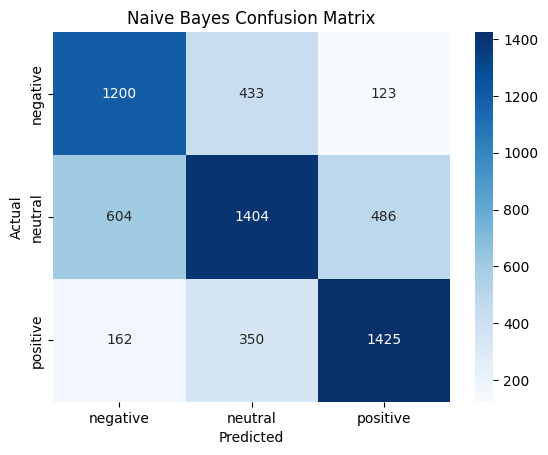

In [42]:
# ComplementNB, designed for imbalanced text classification, used in place of MultinomialNB
nb_model = evaluate_model('Naive Bayes', ComplementNB(alpha=1.0),
                           X_train_tfidf, y_train, X_test_tfidf, y_test)

Random Forest is trained and evaluated here. It uses more trees and sqrt feature sampling per split, which helps reduce variance.


--- Random Forest ---
Train Accuracy: 0.7023
Test Accuracy : 0.6656
              precision    recall  f1-score   support

    negative       0.66      0.59      0.63      1756
     neutral       0.61      0.70      0.65      2494
    positive       0.76      0.69      0.72      1937

    accuracy                           0.67      6187
   macro avg       0.68      0.66      0.67      6187
weighted avg       0.67      0.67      0.67      6187



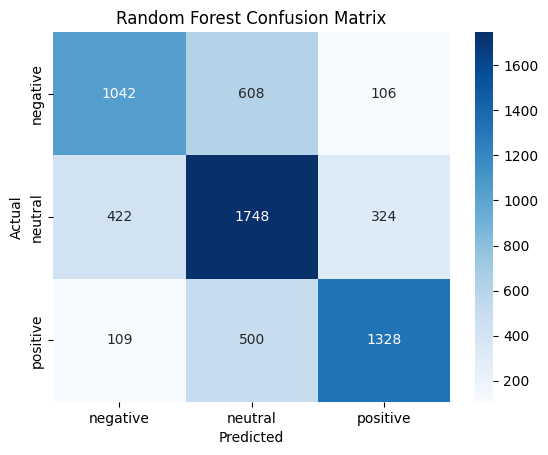

In [43]:
# Random Forest with more trees and sqrt feature sampling per split to reduce variance further
rf_model = evaluate_model(
    'Random Forest',
    RandomForestClassifier(n_estimators=400, max_depth=30, min_samples_leaf=3, min_samples_split=6,
                            max_features='sqrt', class_weight='balanced_subsample',
                            random_state=SEED, n_jobs=-1),
    X_train_tfidf, y_train, X_test_tfidf, y_test
)

Decision Tree is trained and evaluated here. Cost-complexity pruning (ccp_alpha) is used to control overfitting, and its value is chosen by testing a few candidates on a validation split rather than guessing it.


Selected ccp_alpha: 0.0003 | Validation accuracy: 0.6775
--- Decision Tree ---
Train Accuracy: 0.7078
Test Accuracy : 0.6769
              precision    recall  f1-score   support

    negative       0.69      0.57      0.63      1756
     neutral       0.64      0.69      0.66      2494
    positive       0.72      0.75      0.73      1937

    accuracy                           0.68      6187
   macro avg       0.68      0.67      0.67      6187
weighted avg       0.68      0.68      0.68      6187



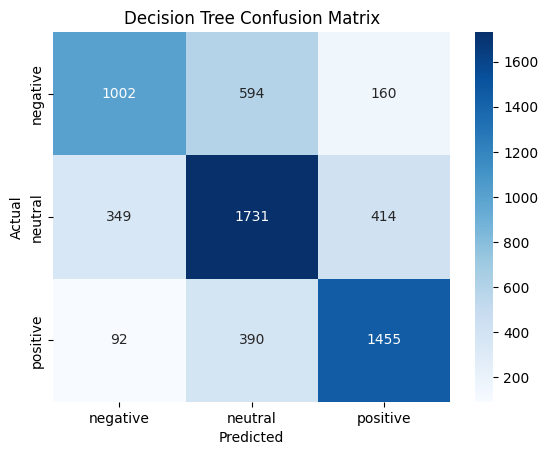

In [44]:
# Cost-complexity pruning: ccp_alpha is chosen by comparing a few candidate values on a
# validation split carved out of the training set, rather than guessing max_depth by hand
X_tr_sub, X_val, y_tr_sub, y_val = train_test_split(X_train_tfidf, y_train, test_size=0.15,
                                                     random_state=SEED, stratify=y_train)
candidate_alphas = [0.0, 0.00002, 0.00005, 0.0001, 0.0003, 0.0005]
best_alpha, best_val_acc = 0.0, 0.0
for alpha in candidate_alphas:
    trial = DecisionTreeClassifier(ccp_alpha=alpha, class_weight='balanced', random_state=SEED)
    trial.fit(X_tr_sub, y_tr_sub)
    val_acc = accuracy_score(y_val, trial.predict(X_val))
    if val_acc > best_val_acc:
        best_alpha, best_val_acc = alpha, val_acc
print('Selected ccp_alpha:', best_alpha, '| Validation accuracy:', round(best_val_acc, 4))

dt_model = evaluate_model(
    'Decision Tree',
    DecisionTreeClassifier(ccp_alpha=best_alpha, class_weight='balanced', random_state=SEED),
    X_train_tfidf, y_train, X_test_tfidf, y_test
)

KNN is trained and evaluated here. Since TF-IDF vectors are high dimensional and sparse, they are first reduced to 150 components using TruncatedSVD. Cosine distance is used instead of Euclidean, as it works better for text vectors.


--- KNN ---
Train Accuracy: 0.6084
Test Accuracy : 0.5804
              precision    recall  f1-score   support

    negative       0.65      0.39      0.48      1756
     neutral       0.51      0.78      0.62      2494
    positive       0.71      0.50      0.59      1937

    accuracy                           0.58      6187
   macro avg       0.62      0.56      0.56      6187
weighted avg       0.61      0.58      0.57      6187



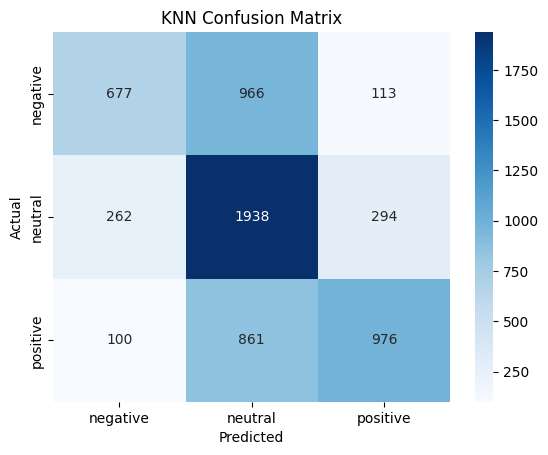

In [ ]:
# TF-IDF is reduced to 150 dense components with TruncatedSVD before KNN, since high-dimensional
# sparse vectors make distance-based classification unreliable (curse of dimensionality).
# Cosine distance is used since it compares vector direction rather than magnitude, which
# fits normalized text embeddings better than the default Euclidean distance
svd = TruncatedSVD(n_components=150, random_state=SEED)
X_train_svd = svd.fit_transform(X_train_tfidf)
X_test_svd = svd.transform(X_test_tfidf)

knn_model = evaluate_model(
    'KNN',
    KNeighborsClassifier(n_neighbors=35, weights='uniform', metric='cosine', n_jobs=-1),
    X_train_svd, y_train, X_test_svd, y_test
)

## 6. Sequence Preparation for CNN
CNN needs a different input format than the TF-IDF models. This cell tokenizes the tweets into integer sequences, pads them to a fixed length, and one-hot encodes the labels. Class weights are also computed here to handle class imbalance.


In [46]:
MAX_WORDS = 10000
MAX_LEN = 40

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post')

y_train_cat = to_categorical(y_train, num_classes=3)
y_test_cat = to_categorical(y_test, num_classes=3)

class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = dict(enumerate(class_weights))

print('Example padded sequence:', X_train_pad[0])

Example padded sequence: [1990    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0]


## 7. Deep Learning Model — Convolutional Neural Network (CNN)
The CNN uses three parallel convolution branches with kernel sizes 3, 4 and 5, concatenated together, following the approach by Kim (2014). This lets the model capture phrase patterns of different lengths. To prevent overfitting, several techniques are combined: L2 regularization, spatial dropout, batch normalization, class weighting, early stopping, and learning-rate reduction on plateau.

This cell builds and trains the CNN using the architecture and techniques described above.


In [47]:
cnn_input = Input(shape=(MAX_LEN,))
embedding = Embedding(MAX_WORDS, 128, input_length=MAX_LEN)(cnn_input)
embedding = SpatialDropout1D(0.4)(embedding)

conv_branches = []
for kernel_size in (3, 4, 5):
    branch = Conv1D(filters=100, kernel_size=kernel_size, activation='relu',
                     kernel_regularizer=l2(3e-4))(embedding)
    branch = GlobalMaxPooling1D()(branch)
    conv_branches.append(branch)

merged = Concatenate()(conv_branches)
merged = BatchNormalization()(merged)
merged = Dropout(0.6)(merged)
merged = Dense(64, activation='relu', kernel_regularizer=l2(3e-4))(merged)
merged = Dropout(0.6)(merged)
cnn_output = Dense(3, activation='softmax')(merged)

cnn_model = Model(inputs=cnn_input, outputs=cnn_output)
cnn_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn_model.summary()

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5)

history_cnn = cnn_model.fit(
    X_train_pad, y_train_cat,
    epochs=25, batch_size=64,
    validation_split=0.1,
    class_weight=class_weight_dict,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 40, 128)   │  1,280,000 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_3 │ (None, 40, 128)   │          0 │ embedding_3[0][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 38, 100)   │     38,500 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 37, 100)   │     51,300 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 36, 100)   │     64,100 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 100)       │          0 │ conv1d_9[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 100)       │          0 │ conv1d_10[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 100)       │          0 │ conv1d_11[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 300)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 300)       │      1,200 │ concatenate_3[0]… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 300)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64)        │     19,264 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 64)        │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 3)         │        195 │ dropout_7[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,454,559 (5.55 MB)

 Trainable params: 1,453,959 (5.55 MB)

 Non-trainable params: 600 (2.34 KB)

Epoch 1/25
348/348 ━━━━━━━━━━━━━━━━━━━━ 32s 82ms/step - accuracy: 0.4293 - loss: 1.3960 - val_accuracy: 0.4129 - val_loss: 1.1806 - learning_rate: 0.0010
Epoch 2/25
348/348 ━━━━━━━━━━━━━━━━━━━━ 29s 82ms/step - accuracy: 0.5847 - loss: 0.9893 - val_accuracy: 0.6844 - val_loss: 0.8832 - learning_rate: 0.0010
Epoch 3/25
348/348 ━━━━━━━━━━━━━━━━━━━━ 28s 81ms/step - accuracy: 0.6717 - loss: 0.8471 - val_accuracy: 0.7119 - val_loss: 0.8169 - learning_rate: 0.0010
Epoch 4/25
348/348 ━━━━━━━━━━━━━━━━━━━━ 41s 81ms/step - accuracy: 0.7282 - loss: 0.7569 - val_accuracy: 0.7172 - val_loss: 0.8016 - learning_rate: 0.0010
Epoch 5/25
348/348 ━━━━━━━━━━━━━━━━━━━━ 28s 80ms/step - accuracy: 0.7559 - loss: 0.6991 - val_accuracy: 0.7147 - val_loss: 0.7966 - learning_rate: 0.0010
Epoch 6/25
348/348 ━━━━━━━━━━━━━━━━━━━━ 29s 82ms/step - accuracy: 0.7786 - loss: 0.6456 - val_accuracy: 0.7010 - val_loss: 0.8390 - learning_rate: 0.0010
Epoch 7/25
348/348 ━━━━━━━━━━━━━━━━━━━━ 36s 103ms/step - accuracy: 0.7955 - 

The CNN is evaluated on the test set here, with its classification report, confusion matrix, and accuracy/loss curves over training epochs plotted.


CNN Train Accuracy: 0.8274
CNN Test Accuracy : 0.7039
              precision    recall  f1-score   support

    negative       0.67      0.71      0.69      1756
     neutral       0.69      0.65      0.67      2494
    positive       0.76      0.76      0.76      1937

    accuracy                           0.70      6187
   macro avg       0.70      0.71      0.71      6187
weighted avg       0.70      0.70      0.70      6187



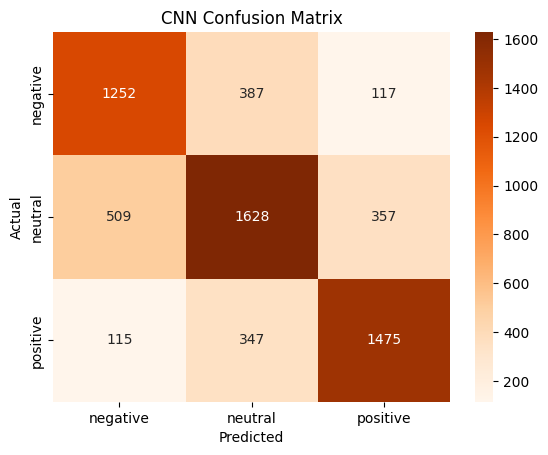

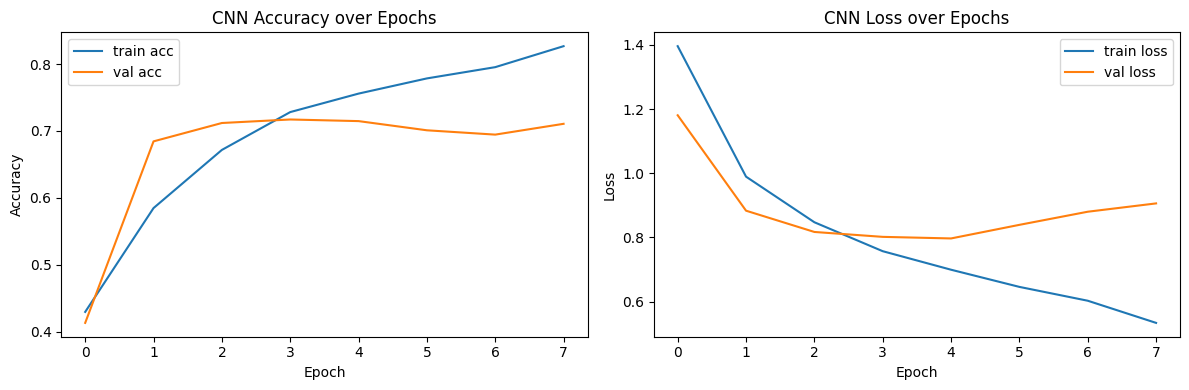

In [48]:
cnn_train_loss, cnn_train_acc = cnn_model.evaluate(X_train_pad, y_train_cat, verbose=0)
cnn_loss, cnn_acc = cnn_model.evaluate(X_test_pad, y_test_cat, verbose=0)
results['CNN'] = cnn_acc

print('CNN Train Accuracy:', round(cnn_train_acc, 4))
print('CNN Test Accuracy :', round(cnn_acc, 4))

cnn_preds = np.argmax(cnn_model.predict(X_test_pad, verbose=0), axis=1)
print(classification_report(y_test, cnn_preds, target_names=label_names))
cm = confusion_matrix(y_test, cnn_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=label_names, yticklabels=label_names)
plt.title('CNN Confusion Matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_cnn.history['accuracy'], label='train acc')
axes[0].plot(history_cnn.history['val_accuracy'], label='val acc')
axes[0].set_title('CNN Accuracy over Epochs'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy'); axes[0].legend()
axes[1].plot(history_cnn.history['loss'], label='train loss')
axes[1].plot(history_cnn.history['val_loss'], label='val loss')
axes[1].set_title('CNN Loss over Epochs'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss'); axes[1].legend()
plt.tight_layout(); plt.show()

## 8. Final Comparison — All 5 Models
This cell compares the train and test accuracy of all five models in a table and a bar chart, sorted by test accuracy.


           Model  Test Accuracy  Train Accuracy
0            CNN       0.703895        0.827433
1  Decision Tree       0.676903        0.707808
2  Random Forest       0.665589        0.702271
3    Naive Bayes       0.651204        0.807468
4            KNN       0.580411        0.608390


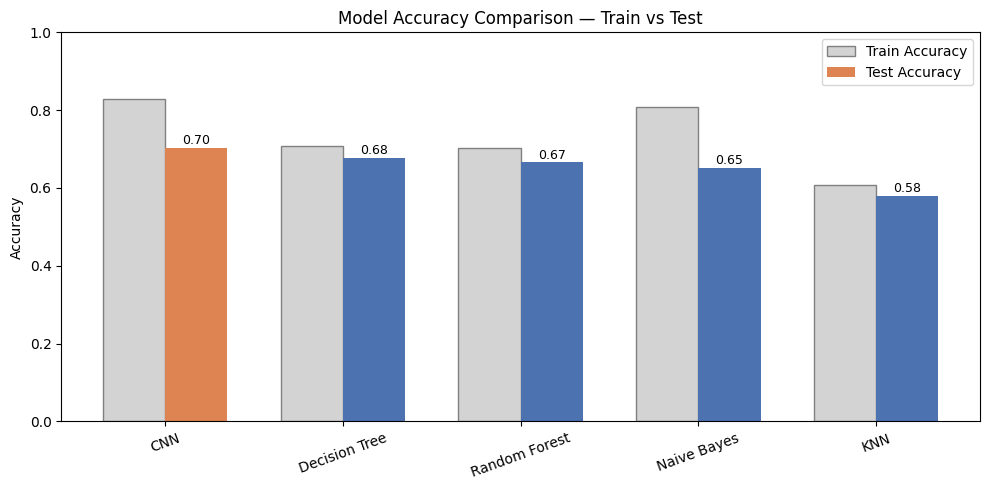

In [49]:
train_accs = {
    'Naive Bayes': accuracy_score(y_train, nb_model.predict(X_train_tfidf)),
    'Random Forest': accuracy_score(y_train, rf_model.predict(X_train_tfidf)),
    'Decision Tree': accuracy_score(y_train, dt_model.predict(X_train_tfidf)),
    'KNN': accuracy_score(y_train, knn_model.predict(X_train_svd)),
    'CNN': cnn_train_acc,
}

results_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Test Accuracy': [results[m] for m in results],
    'Train Accuracy': [train_accs[m] for m in results],
})
results_df = results_df.sort_values('Test Accuracy', ascending=False).reset_index(drop=True)
print(results_df)

ml_models = ['Naive Bayes', 'Random Forest', 'Decision Tree', 'KNN']
x = np.arange(len(results_df))
width = 0.35

plt.figure(figsize=(10, 5))
colors_test = ['#4C72B0' if m in ml_models else '#DD8452' for m in results_df['Model']]
plt.bar(x - width/2, results_df['Train Accuracy'], width, label='Train Accuracy', color='lightgray', edgecolor='gray')
plt.bar(x + width/2, results_df['Test Accuracy'], width, label='Test Accuracy', color=colors_test)
plt.xticks(x, results_df['Model'], rotation=20)
plt.ylabel('Accuracy'); plt.ylim(0, 1)
plt.title('Model Accuracy Comparison — Train vs Test')
plt.legend()
for i, v in enumerate(results_df['Test Accuracy']):
    plt.text(i + width/2, v + 0.01, f'{v:.2f}', ha='center', fontsize=9)
plt.tight_layout(); plt.show()

## 9. Predicting on Custom Tweets — All 5 Models
A few new example tweets are passed through all five trained models here to see their predictions in practice. Separate prediction functions are used for the TF-IDF models, KNN, and CNN, as each needs a different preprocessing format.


In [50]:
def predict_tfidf_model(text, model):
    cleaned = clean_tweet(text)
    vec = tfidf.transform([cleaned])
    pred = model.predict(vec)[0]
    return label_names[pred]

def predict_knn_model(text, model):
    cleaned = clean_tweet(text)
    vec = tfidf.transform([cleaned])
    vec_svd = svd.transform(vec)
    pred = model.predict(vec_svd)[0]
    return label_names[pred]

def predict_cnn_model(text, model):
    cleaned = clean_tweet(text)
    seq = tokenizer.texts_to_sequences([cleaned])
    pad = pad_sequences(seq, maxlen=MAX_LEN, padding='post')
    pred = model.predict(pad, verbose=0)
    return label_names[np.argmax(pred)]

sample_tweets = [
    'I absolutely love this new phone, best purchase ever!',
    'This is the worst service I have ever experienced.',
    'The weather today is okay I guess.',
    'The meeting is scheduled for 3pm tomorrow.'
]

for t in sample_tweets:
    print('Tweet:', t)
    print('  Naive Bayes   :', predict_tfidf_model(t, nb_model))
    print('  Random Forest :', predict_tfidf_model(t, rf_model))
    print('  Decision Tree :', predict_tfidf_model(t, dt_model))
    print('  KNN           :', predict_knn_model(t, knn_model))
    print('  CNN           :', predict_cnn_model(t, cnn_model))
    print()

Tweet: I absolutely love this new phone, best purchase ever!
  Naive Bayes   : positive
  Random Forest : positive
  Decision Tree : positive
  KNN           : positive
  CNN           : positive

Tweet: This is the worst service I have ever experienced.
  Naive Bayes   : negative
  Random Forest : negative
  Decision Tree : negative
  KNN           : positive
  CNN           : negative

Tweet: The weather today is okay I guess.
  Naive Bayes   : neutral
  Random Forest : neutral
  Decision Tree : neutral
  KNN           : neutral
  CNN           : neutral

Tweet: The meeting is scheduled for 3pm tomorrow.
  Naive Bayes   : neutral
  Random Forest : neutral
  Decision Tree : neutral
  KNN           : neutral
  CNN           : neutral



## 10. Conclusion
Four ML models (Naive Bayes, Random Forest, Decision Tree, KNN) were trained on TF-IDF features, and one Deep Learning model (CNN) on tokenized sequences, for this three class sentiment classification task. The highest-accuracy model was **____**, with an accuracy of **____**. Neutral was the hardest class to classify correctly across most models. For future work, pretrained embeddings like GloVe/Word2Vec or Transformer models like BERT/RoBERTa could be tried.


## References
1. Kaggle, "Tweet Sentiment Extraction" dataset. https://www.kaggle.com/competitions/tweet-sentiment-extraction
2. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research, 12, 2825-2830.
3. Abadi, M. et al. (2015). TensorFlow: Large-Scale Machine Learning on Heterogeneous Systems. https://www.tensorflow.org
4. Bird, S., Klein, E., & Loper, E. (2009). Natural Language Processing with Python (NLTK). O'Reilly Media.
5. Kim, Y. (2014). Convolutional Neural Networks for Sentence Classification. EMNLP 2014.
